In [1]:
from pyclassrich.gnps import Proteosafe
import matplotlib.pyplot as plt

from pyclassrich.models import class_enrichment, impact_plot, ont_graph, get_ont_graph
from pyclassrich.utils import *
import pandas as pd
import json

from pyclassrich.stats import *

In [2]:
params = {
    "mzmine": False,
    "mzmine_batch": False,
    "desc": 'description',
    "gnps_taskid": '',
    "gnps_workflow": '',
    "gnps_nap": False,
    "nap_taskid": '',
    "classify": True,
    "normalization": {
        "perform": True,
        "type": 'TIC'
    },
    "enrich": True,
    "comparison": {
        "classes": 'A,C',
        "field": 'ATTRIBUTE_Genotype',
        "test": 'ttest',
        "vthr": 0.5
    },
    "summarize": True,
    "pcoa": True,
    "pcoa_metric": 'canberra',
    "pcoa_norm": True,
    "pcoa_scale": True,
    "email": 'email@gmail.com',
    "chw": '',
    "type": 'canopus',
    "canopus_file": ''
}

In [3]:
gnps = Proteosafe('7679c548a8d94307beec24167ed6b9ea', 'FBMN-gnps2')
gnps.get_gnps()
feat = gnps.feat
meta = gnps.meta
meta.filename = meta.filename.str.replace(' Peak area', '')
tabgnps = pd.merge(gnps.gnps, gnps.dbmatch,  left_on='cluster index', right_on='#Scan#', how='left')

In [4]:
annotated = tabgnps[['cluster index', 'SpectrumID', 'Smiles', 'INCHI',  'InChIKey', 'superclass','class', 'subclass']]
annotated = annotated.rename(columns={'cluster index': 'cluster.index',  'superclass':'superclass_name', 'class':'class_name', 'subclass':'subclass_name', 'InChIKey':'InchiKey'})

annotated['Identifier'] = annotated['InChI'] = annotated['superclass_id'] = annotated['class_id'] = annotated['subclass_id'] = annotated['conflict'] = annotated['ginchikey'] = annotated['InChI'] = annotated['kingdom_name'] = ''
annotated['Score'] = 0

 
annotated = annotated[['cluster.index', 'SpectrumID', 'Smiles', 'INCHI', 'Identifier', 'Score',
                      'InChI', 'kingdom_name', 'superclass_name', 'class_name',
                      'subclass_name', 'superclass_id', 'class_id', 'subclass_id', 'conflict',
                      'ginchikey', 'InchiKey']]

tabgnps = tabgnps.rename(columns={'cluster index': 'cluster.index', 'parent mass':'parent.mass', 'SpectrumID':'LibraryID'})

In [5]:
params['comparison']['classes'] = '3,5' 
params['comparison']['field'] = 'ATTRIBUTE_Fragment'
params['comparison']['test'] = 'ttest'

In [6]:
df = univariate(annotated, tabgnps,
                params, feat, meta)

In [7]:
df.head()

,cluster.index,parent.mass,RTMean,LibraryID,Identifier,InchiKey,kingdom_name,superclass_name,superclass_id,class_name,...,subclass_name,subclass_id,Smiles,InChI,row ID,row m/z,row retention time,fchange,pval,cpval
0,1,363.217539,17.130065,CCMSLIB00006117011,,JYGXADMDTFJGBT-VWUMJDOOSA-N,,Lipids and lipid-like molecules,,Steroids and steroid derivatives,...,Hydroxysteroids,,C[C@]12CCC(=O)C=C1CC[C@@H]3[C@@H]2[C@H](C[C@]4...,,1,363.217539,17.130065,0.779415,0.301114,0.447370
1,2,593.276384,36.894470,CCMSLIB00010128702,,NSFSLUUZQIAOOX-LDCXZXNSSA-N,,Organoheterocyclic compounds,,Tetrapyrroles and derivatives,...,Chlorins,,OC(CC[C@H]1[C@@H](C2=N/C1=C([C@@H](C(OC)=O)C3=...,,2,593.276384,36.894470,3.024936,0.105010,0.325787
2,3,609.271772,35.783250,NaN,,NaN,,NaN,,NaN,...,NaN,,NaN,,3,609.271772,35.783250,10.455863,0.001910,0.085200
3,4,725.426315,17.130588,CCMSLIB00000004408,,JYGXADMDTFJGBT-VWUMJDOOSA-N,,Lipids and lipid-like molecules,,Steroids and steroid derivatives,...,Hydroxysteroids,,C[C@]12CCC(=O)C=C1CC[C@@H]3[C@@H]2[C@H](C[C@]4...,,4,725.426315,17.130588,0.727588,0.306859,0.449008
4,5,343.117905,29.522792,NaN,,NaN,,NaN,,NaN,...,NaN,,NaN,,5,343.117905,29.522792,86.760885,0.035588,0.325787


In [8]:
# old format from olakunle
canopus = pd.read_csv('canopus_compound_summary.tsv', sep='\t')
canopus.head()

,id,molecularFormula,adduct,NPC#pathway,NPC#pathway Probability,NPC#superclass,NPC#superclass Probability,NPC#class,NPC#class Probability,ClassyFire#most specific class,ClassyFire#most specific class Probability,ClassyFire#level 5,ClassyFire#level 5 Probability,ClassyFire#subclass,ClassyFire#subclass Probability,ClassyFire#class,ClassyFire#class Probability,ClassyFire#superclass,ClassyFire#superclass probability,ClassyFire#all classifications
0,1_hypoxia_GenA&C_3,C12H28N2,[M + H]+,Alkaloids,"0,875980735",Ornithine alkaloids,"0,919554949",Polyamines,"0,932699919",Trialkylamines,"0,854360342",Tertiary amines,"0,813410819",Amines,"0,99836117",Organonitrogen compounds,1,Organic nitrogen compounds,"0,999999881",Organic compounds; Organonitrogen compounds; D...
1,2_hypoxia_GenA&C_7,C2H3NO5S,[M + H]+,Amino acids and Peptides,"0,898182511",Small peptides,"0,921811879",Aminoacids,"0,794122338",Carboxylic acid derivatives,"0,546446383",NaN,NaN,Carboxylic acid derivatives,"0,546446383",Carboxylic acids and derivatives,"0,953606129",Organic acids and derivatives,"0,993620694",Organic compounds; Organic acids and derivativ...
2,3_hypoxia_GenA&C_8,C8H18O3,[M + Na]+,Fatty acids,"0,937867641",Fatty acyls,"0,654745996",Fatty alcohols,"0,826120853",Fatty alcohols,"0,689763665",NaN,NaN,Fatty alcohols,"0,689763665",Fatty Acyls,"0,8762784",Lipids and lipid-like molecules,"0,669634879",Organic compounds; Lipids and lipid-like molec...
3,4_hypoxia_GenA&C_22,C7H11NO2,[M + H3N + H]+,Fatty acids,"0,782327294",Fatty amides,"0,580163658",Wax monoesters,"0,671413898",N-acyl amines,"0,947950125",N-acyl amines,"0,947950125",Fatty amides,"0,903751314",Fatty Acyls,"0,961429179",Lipids and lipid-like molecules,"0,939273119",Organic compounds; Lipids and lipid-like molec...
4,5_hypoxia_GenA&C_26,C9H10N2S,[M + H]+,Alkaloids,"0,942300856",Anthranilic acid alkaloids,"0,503394186",Pyridine alkaloids,"0,333105117",Dialkylarylamines,"0,661802948",Tertiary amines,"0,346091002",Amines,"0,809939921",Organonitrogen compounds,"0,999967694",Organic nitrogen compounds,1,Organic compounds; Organoheterocyclic compound...


In [9]:
canopus.iloc[0,0].split('_')[-1]

'3'

In [10]:
#canopus['mappingFeatureId'] = canopus.id.apply(lambda a: a.split('_')[-1]).astype(int)

In [11]:
# new format with mappingFeatureId field
canopus = pd.read_csv('canopus_formula_summary.tsv', sep='\t')
canopus = canopus.rename(columns={'mappingFeatureId': 'cluster index'})
uni = pd.merge(df,
               canopus[['cluster index', 'ClassyFire#most specific class']],
               left_on='row ID', right_on='cluster index',
               how='left')


In [12]:
uni.head()

,cluster.index,parent.mass,RTMean,LibraryID,Identifier,InchiKey,kingdom_name,superclass_name,superclass_id,class_name,...,Smiles,InChI,row ID,row m/z,row retention time,fchange,pval,cpval,cluster index,ClassyFire#most specific class
0,1,363.217539,17.130065,CCMSLIB00006117011,,JYGXADMDTFJGBT-VWUMJDOOSA-N,,Lipids and lipid-like molecules,,Steroids and steroid derivatives,...,C[C@]12CCC(=O)C=C1CC[C@@H]3[C@@H]2[C@H](C[C@]4...,,1,363.217539,17.130065,0.779415,0.301114,0.447370,1.0,"Gluco/mineralocorticoids, progestogins and der..."
1,2,593.276384,36.894470,CCMSLIB00010128702,,NSFSLUUZQIAOOX-LDCXZXNSSA-N,,Organoheterocyclic compounds,,Tetrapyrroles and derivatives,...,OC(CC[C@H]1[C@@H](C2=N/C1=C([C@@H](C(OC)=O)C3=...,,2,593.276384,36.894470,3.024936,0.105010,0.325787,2.0,Tetrapyrroles and derivatives
2,3,609.271772,35.783250,NaN,,NaN,,NaN,,NaN,...,NaN,,3,609.271772,35.783250,10.455863,0.001910,0.085200,3.0,Tetrapyrroles and derivatives
3,4,725.426315,17.130588,CCMSLIB00000004408,,JYGXADMDTFJGBT-VWUMJDOOSA-N,,Lipids and lipid-like molecules,,Steroids and steroid derivatives,...,C[C@]12CCC(=O)C=C1CC[C@@H]3[C@@H]2[C@H](C[C@]4...,,4,725.426315,17.130588,0.727588,0.306859,0.449008,4.0,"Gluco/mineralocorticoids, progestogins and der..."
4,5,343.117905,29.522792,NaN,,NaN,,NaN,,NaN,...,NaN,,5,343.117905,29.522792,86.760885,0.035588,0.325787,5.0,1-benzopyrans


In [13]:
uni.drop(['class_name'], axis=1, inplace=True)
uni.rename(columns={'ClassyFire#most specific class': 'class_name'}, inplace=True)
uni['class_name'] = uni['class_name'].fillna('')

chemrich = uni.copy().loc[~uni['cluster.index'].isnull(),
                         ['Identifier', 'class_name', 'InChI',
                          'pval', 'fchange']]

chemrich.columns = ['Compound_Name', 'Class', 'InChI', 'pvalue', 'foldchange']
chemrich

,Compound_Name,Class,InChI,pvalue,foldchange
0,,"Gluco/mineralocorticoids, progestogins and der...",,0.301114,0.779415
1,,Tetrapyrroles and derivatives,,0.105010,3.024936
2,,Tetrapyrroles and derivatives,,0.001910,10.455863
3,,"Gluco/mineralocorticoids, progestogins and der...",,0.306859,0.727588
4,,1-benzopyrans,,0.035588,86.760885
...,...,...,...,...,...
359,,Amino acids and derivatives,,0.169875,0.794704
360,,Nitroaromatic compounds,,0.169875,0.794704
361,,Benzene and substituted derivatives,,0.169875,0.794704
362,,Benzenoids,,0.169875,0.794704


In [14]:
uni.head()

,cluster.index,parent.mass,RTMean,LibraryID,Identifier,InchiKey,kingdom_name,superclass_name,superclass_id,class_id,...,Smiles,InChI,row ID,row m/z,row retention time,fchange,pval,cpval,cluster index,class_name
0,1,363.217539,17.130065,CCMSLIB00006117011,,JYGXADMDTFJGBT-VWUMJDOOSA-N,,Lipids and lipid-like molecules,,,...,C[C@]12CCC(=O)C=C1CC[C@@H]3[C@@H]2[C@H](C[C@]4...,,1,363.217539,17.130065,0.779415,0.301114,0.447370,1.0,"Gluco/mineralocorticoids, progestogins and der..."
1,2,593.276384,36.894470,CCMSLIB00010128702,,NSFSLUUZQIAOOX-LDCXZXNSSA-N,,Organoheterocyclic compounds,,,...,OC(CC[C@H]1[C@@H](C2=N/C1=C([C@@H](C(OC)=O)C3=...,,2,593.276384,36.894470,3.024936,0.105010,0.325787,2.0,Tetrapyrroles and derivatives
2,3,609.271772,35.783250,NaN,,NaN,,NaN,,,...,NaN,,3,609.271772,35.783250,10.455863,0.001910,0.085200,3.0,Tetrapyrroles and derivatives
3,4,725.426315,17.130588,CCMSLIB00000004408,,JYGXADMDTFJGBT-VWUMJDOOSA-N,,Lipids and lipid-like molecules,,,...,C[C@]12CCC(=O)C=C1CC[C@@H]3[C@@H]2[C@H](C[C@]4...,,4,725.426315,17.130588,0.727588,0.306859,0.449008,4.0,"Gluco/mineralocorticoids, progestogins and der..."
4,5,343.117905,29.522792,NaN,,NaN,,NaN,,,...,NaN,,5,343.117905,29.522792,86.760885,0.035588,0.325787,5.0,1-benzopyrans


In [15]:
uni.to_csv('uni.csv', index=None)

In [16]:
chemrich.Compound_Name = range(chemrich.shape[0])
chemrich

,Compound_Name,Class,InChI,pvalue,foldchange
0,0,"Gluco/mineralocorticoids, progestogins and der...",,0.301114,0.779415
1,1,Tetrapyrroles and derivatives,,0.105010,3.024936
2,2,Tetrapyrroles and derivatives,,0.001910,10.455863
3,3,"Gluco/mineralocorticoids, progestogins and der...",,0.306859,0.727588
4,4,1-benzopyrans,,0.035588,86.760885
...,...,...,...,...,...
359,359,Amino acids and derivatives,,0.169875,0.794704
360,360,Nitroaromatic compounds,,0.169875,0.794704
361,361,Benzene and substituted derivatives,,0.169875,0.794704
362,362,Benzenoids,,0.169875,0.794704


In [17]:
clusterdf = class_enrichment(chemrich, cfield='Class', nfield='Compound_Name')

RDKit ERROR: [10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 
[10:59:19] ERROR: 

In [18]:
clusterdf

,name,pvalues,adjustedpvalue,keycpdname,alteredMetabolites,upcount,downcount,upratio,altratio,csize,xlogp
0,Tetrapyrroles and derivatives,0.000042,0.000291,2,4,4,0,1.00,0.666667,6,0
1,1-benzopyrans,0.052609,0.276197,8,2,2,0,1.00,0.666667,3,0
2,Chromones,1.0,1.0,7,0,0,0,NaN,0.000000,3,0
3,Alpha amino acids and derivatives,0.0,0.0,15,4,3,1,0.75,0.160000,25,0
4,Triterpenoids,1.0,1.0,10,0,0,0,NaN,0.000000,6,0
5,Benzenoids,1.0,1.0,11,1,1,0,1.00,0.200000,5,0
6,N-acyl-alpha amino acids and derivatives,1.0,1.0,151,0,0,0,NaN,0.000000,19,0
7,Lipids and lipid-like molecules,1.0,1.0,29,1,1,0,1.00,0.333333,3,0
8,Anisoles,1.0,1.0,37,1,1,0,1.00,0.200000,5,0
9,Flavonoid-3-O-glycosides,1.0,1.0,38,0,0,0,NaN,0.000000,6,0


In [19]:
!wget https://raw.githubusercontent.com/computational-chemical-biology/basic_data_manipulation/refs/heads/master/scripts/classyfire_xlogp_lookup.py

--2026-09-23 10:59:31--  https://raw.githubusercontent.com/computational-chemical-biology/basic_data_manipulation/refs/heads/master/scripts/classyfire_xlogp_lookup.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 383057 (374K) [text/plain]
Saving to: ‘classyfire_xlogp_lookup.py.2’

classyfire_xlogp_lo 100%[===================>] 374.08K  --.-KB/s    in 0.03s   

2026-09-23 10:59:31 (11.7 MB/s) - ‘classyfire_xlogp_lookup.py.2’ saved [383057/383057]



In [20]:
import classyfire_xlogp_lookup

In [21]:
clusterdf.name.apply(lambda a: classyfire_xlogp_lookup.get_median_xlogp(a))

0     4.6
1     4.7
2     4.2
3     3.5
4     7.2
5     3.8
6     2.6
7     4.1
8     3.5
9    -0.4
10    3.7
11   -1.3
12    2.4
13   -1.8
14   -0.4
15    3.0
16    1.5
17    3.7
18   -2.3
19    2.2
20    0.6
Name: name, dtype: float64

In [22]:
clusterdf['xlogp'] = clusterdf.name.apply(lambda a: classyfire_xlogp_lookup.get_median_xlogp(a))

In [23]:
clusterdf.sort_values('pvalues')

,name,pvalues,adjustedpvalue,keycpdname,alteredMetabolites,upcount,downcount,upratio,altratio,csize,xlogp
3,Alpha amino acids and derivatives,0.0,0.0,15,4,3,1,0.75,0.160000,25,3.5
11,Amino acids and derivatives,0.0,0.000001,87,2,1,1,0.50,0.080000,25,-1.3
0,Tetrapyrroles and derivatives,0.000042,0.000291,2,4,4,0,1.00,0.666667,6,4.6
1,1-benzopyrans,0.052609,0.276197,8,2,2,0,1.00,0.666667,3,4.7
18,Amino acids,1.0,1.0,246,0,0,0,NaN,0.000000,3,-2.3
17,Phenol ethers,1.0,1.0,156,0,0,0,NaN,0.000000,4,3.7
16,Aminopyrimidines and derivatives,1.0,1.0,350,0,0,0,NaN,0.000000,3,1.5
15,Alpha amino acid amides,1.0,1.0,163,0,0,0,NaN,0.000000,3,3.0
14,Glycosylamines,1.0,1.0,131,0,0,0,NaN,0.000000,7,-0.4
13,Hexoses,1.0,1.0,79,0,0,0,NaN,0.000000,8,-1.8


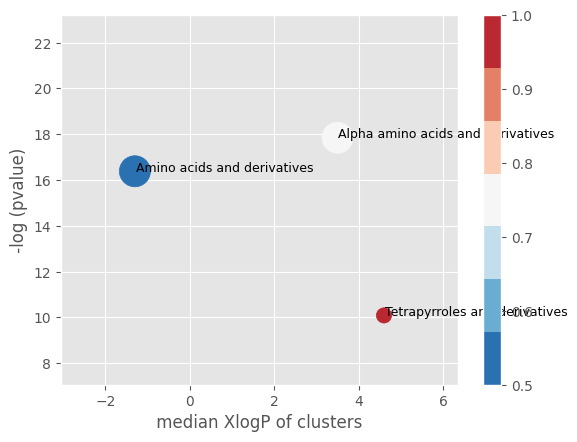

In [24]:
impact_plot(clusterdf, chemrich, cfield='Class', nfield='Compound_Name',
            scaling_factor=20, top=10, xshift=0.5)

In [30]:
ont_graph(clusterdf, 'ont.graphml')